# Everpure | Synthetic reviewer demonstration (end to end)

**SYNTHETIC REVIEWER DEMONSTRATION — INVENTED ACCOUNTS, NOT EVERPURE DATA.**

This notebook runs the frozen production code on 22 invented `SYN_` accounts so a reviewer without the confidential assessment CSV can execute every stage: source hygiene, hierarchy resolution, DuckDB SQL (CTEs, LAG/LEAD, DENSE_RANK), the synthetic Cox lane, assumed-hazard reactivation probabilities, Monte Carlo NPV and the GTM routing rules. Numbers below describe the invented fixture only; the authoritative Everpure results are in the frozen aggregate outputs and the submission PDF.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from everpure_case.reviewer_demo import LABEL, run_reviewer_demo
from everpure_case.survival_synthetic import generate_synthetic_cohort, fit_synthetic_cox
pd.set_option('display.width', 160)
demo = run_reviewer_demo(ROOT, simulations=1000)
display(Markdown(f'**{LABEL}**'))
display(pd.Series(demo['checks'], name='check'))

**SYNTHETIC REVIEWER DEMONSTRATION — INVENTED ACCOUNTS, NOT EVERPURE DATA**

fixture_ids_invented                     True
phase1_reconciles                        True
duplicate_ids_flagged                       2
sentinels_excluded                       True
probabilities_monotone_in_horizon        True
max_abs_mc_z                         1.324318
channels_valid                           True
execution_authorized_count                  0
identity_example_rule                      R2
Name: check, dtype: object

## 1. Injected defects in the invented source rows

In [2]:
display(demo['raw'].drop(columns='source_row_number'))

,account_id,parent_account_id,region,last_booking_date,contract_start_date,years_inactive,historical_spend_usd,discount_tier_pct,sfdc_health_score,partner_managed,open_support_tickets,monthly_usage_gb
0,SYN_R01,,EMEA - France,2021-03-15,2019-02-01,5.6,1250000,0.15,Green,1.0,1,52000
1,SYN_C01,SYN_R01,EMEA - France,2021-07-02,2020-01-10,5.3,640000,0.25,Yellow,1.0,2,18000
2,SYN_C02,SYN_R01,emea - france,2022-01-20,2020-06-30,4.7,410000,0.35,nan,0.0,0,41000
3,SYN_C03,SYN_R01,EMEA - France,2020-11-05,2019-09-14,5.9,220000,0.45,Green,,3,9000
4,SYN_R02,,AMER - US West,2022-04-18,2021-01-04,4.5,1800000,0.05,Green,0.0,0,64000
5,SYN_C04,SYN_R02,amer - us west,2021-09-09,2020-03-03,5.1,530000,0.15,Red,0.0,1,22000
6,SYN_C05,SYN_R02,AMER - US West,2022-02-14,2021-02-14,4.6,300000,0.25,Missing,0.0,999,47000
7,SYN_C06,SYN_R02,AMER - US West,2019-12-01,2018-11-20,6.9,150000,0.55,Yellow,0.0,6,12000
8,SYN_R03,,APAC - Japan,2020-06-30,2019-05-15,6.3,960000,0.35,Green,,1,30000
9,SYN_C07,SYN_R03,APAC - Japan,2021-05-25,2020-04-01,5.4,480000,0.45,nan,1.0,0,15500


## 2. Cleaning and the exception register

Region strings are trimmed and case-folded; `nan`/`Missing` health and blank partner flags stay unknown with an explicit flag; `999` tickets are excluded from valid counts; duplicate IDs are flagged, never merged.

In [3]:
exceptions = demo['exceptions']
display(exceptions.groupby(['issue_code', 'severity', 'resolution']).size()
        .rename('events').reset_index().sort_values('events', ascending=False))
display(demo['hierarchy'].hierarchy_status.value_counts().rename('rows').to_frame())

,issue_code,severity,resolution,events
7,REGION_NORMALIZED,info,auto_resolved,6
9,UNKNOWN_HEALTH,warning,left_unknown,5
5,MISSING_NUMBER,error,manual_review,3
10,UNRESOLVED_PARTNER,warning,left_unknown,3
8,TICKET_SENTINEL_999,warning,left_unknown,2
0,AMBIGUOUS_ID,error,manual_review,2
1,DUPLICATE_ACCOUNT_ID,error,manual_review,2
2,INACTIVITY_CONTRADICTION,warning,manual_review,1
6,MISSING_PARENT,error,manual_review,1
3,INACTIVITY_VALUE_GAP_6M,warning,manual_review,1


,rows
hierarchy_status,
resolved,19
ambiguous_id,2
missing_parent,1


## 3. DuckDB SQL on the cleaned synthetic accounts

In [4]:
display(Markdown('```sql\n' + (ROOT / 'sql/spend_concentration.sql').read_text(encoding='utf-8') + '\n```'))
display(demo['sql']['spend_concentration'][['root_account_id', 'account_count', 'additive_recorded_spend_usd',
                                            'spend_rank', 'cumulative_share']])
display(demo['sql']['regional_spend'][['region', 'account_count', 'recorded_spend_usd', 'region_spend_rank']])

```sql
-- Additive recorded-spend proxy, not consolidated revenue or recoverable ARR.
WITH account_spend AS (
    SELECT h.root_account_id, a.account_id, a.historical_spend_usd_num AS spend_usd
    FROM accounts a JOIN hierarchy h USING (source_row_number)
    WHERE h.hierarchy_status = 'resolved'
), root_spend AS (
    SELECT root_account_id, COUNT(*) AS account_count,
           SUM(spend_usd) AS additive_recorded_spend_usd
    FROM account_spend GROUP BY root_account_id
), ranked AS (
    SELECT *, DENSE_RANK() OVER (ORDER BY additive_recorded_spend_usd DESC) AS spend_rank,
           SUM(additive_recorded_spend_usd) OVER () AS all_resolved_spend_usd,
           SUM(additive_recorded_spend_usd) OVER (
               ORDER BY additive_recorded_spend_usd DESC, root_account_id
               ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW
           ) AS cumulative_recorded_spend_usd
    FROM root_spend
)
SELECT *, additive_recorded_spend_usd / NULLIF(all_resolved_spend_usd, 0) AS spend_share,
       cumulative_recorded_spend_usd / NULLIF(all_resolved_spend_usd, 0) AS cumulative_share,
       additive_recorded_spend_usd / NULLIF(account_count, 0)
           AS mean_recorded_spend_per_account_usd
FROM ranked ORDER BY spend_rank, root_account_id;

```

,root_account_id,account_count,additive_recorded_spend_usd,spend_rank,cumulative_share
0,SYN_R02,4,2780000.00000000,1,0.24788230
1,SYN_R01,4,2520000.00000000,2,0.47258136
2,SYN_R04,4,2450000.00000000,3,0.69103879
3,SYN_R05,4,1850000.00000000,4,0.85599643
4,SYN_R03,3,1615000.00000000,5,1.00000000


,region,account_count,recorded_spend_usd,region_spend_rank
0,AMER - US West,4,2780000.00000000,1
1,EMEA - France,4,2520000.00000000,2
2,EMEA - Germany,4,2450000.00000000,3
3,APAC - Japan,6,2255000.00000000,4
4,AMER - US East,4,1850000.00000000,5


## 4. Revenue-decay velocity SQL (LAG / LEAD / DENSE_RANK)

The real extract has no account-period revenue, so decay velocity is demonstrated on the separate labeled fiscal-period fixture in `data/synthetic/`.

In [5]:
account_decay, root_decay = demo['decay']
display(account_decay[['account_id', 'fiscal_period_index', 'period_revenue_usd', 'previous_revenue_usd',
                       'next_revenue_usd', 'consecutive_pct_change', 'signed_change_usd_per_period',
                       'comparison_status']])

,account_id,fiscal_period_index,period_revenue_usd,previous_revenue_usd,next_revenue_usd,consecutive_pct_change,signed_change_usd_per_period,comparison_status
0,SYN_A,1,100,<NA>,80,NaN,NaN,first_observation
1,SYN_A,2,80,100,60,-0.200000,-20.0,consecutive
2,SYN_A,3,60,80,40,-0.250000,-20.0,consecutive
3,SYN_A,4,40,60,<NA>,-0.333333,-20.0,consecutive
4,SYN_B,1,50,<NA>,50,NaN,NaN,first_observation
5,SYN_B,2,50,50,70,0.000000,0.0,consecutive
6,SYN_B,4,70,50,<NA>,NaN,10.0,nonconsecutive_gap
7,SYN_C,1,0,<NA>,20,NaN,NaN,first_observation
8,SYN_C,2,20,0,25,NaN,20.0,consecutive_zero_baseline
9,SYN_C,3,25,20,0,0.250000,5.0,consecutive


## 5. Survival analysis

**Lane A** fits a genuine Cox proportional-hazards model to invented event histories and recovers the generating effects. **Lane B** applies the frozen assumption register (`docs/PHASE_2_ASSUMPTIONS.json`) to the invented cohort: P(T ≤ t) = 1 − exp(−λ·t·exp(xβ)).

,covariate,true_generating_coefficient,estimated_log_hazard_coefficient,estimated_hazard_ratio,hazard_ratio_ci_lower_95,hazard_ratio_ci_upper_95
0,health_proxy,0.45,0.505338,1.657546,1.469690,1.869415
1,engagement_proxy,-0.35,-0.359806,0.697812,0.656154,0.742114
2,partner_proxy,0.25,0.220535,1.246744,1.105786,1.405669


n_events                                     1074.000000
n_right_censored                              526.000000
concordance_in_sample                           0.623858
concordance_independent_synthetic_holdout       0.595321
dtype: float64

scenario_name,conservative,base,optimistic
horizon_months,,,
3,0.270,0.536,0.883
6,0.536,1.054,1.719
12,1.054,2.041,3.261


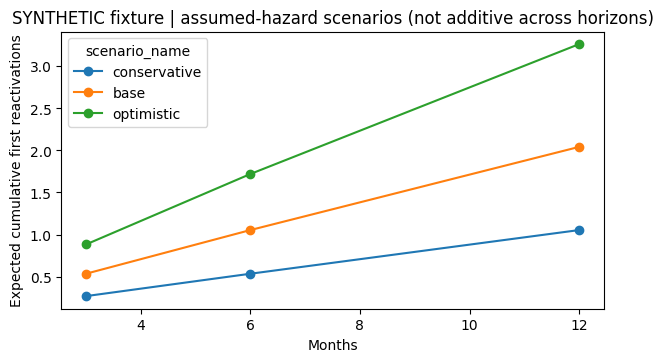

In [6]:
model, coefficients, diagnostics, _ = fit_synthetic_cox(generate_synthetic_cohort())
display(coefficients[['covariate', 'true_generating_coefficient', 'estimated_log_hazard_coefficient',
                      'estimated_hazard_ratio', 'hazard_ratio_ci_lower_95', 'hazard_ratio_ci_upper_95']])
display(pd.Series({k: diagnostics[k] for k in ('n_events', 'n_right_censored', 'concordance_in_sample',
                                               'concordance_independent_synthetic_holdout')}))
summary = demo['survival_summary']
wide = summary.pivot(index='horizon_months', columns='scenario_name', values='expected_reactivations')
display(wide[['conservative', 'base', 'optimistic']].round(3))
ax = wide[['conservative', 'base', 'optimistic']].plot(marker='o', figsize=(7, 3.6))
ax.set(xlabel='Months', ylabel='Expected cumulative first reactivations',
       title='SYNTHETIC fixture | assumed-hazard scenarios (not additive across horizons)')
plt.show()

## 6. Monte Carlo NPV across three discount tiers

Closed-form expected NPV versus 1,000 simulated replications per cell, with common random numbers and the frozen Phase 3 unit economics.

In [7]:
cells = demo['nine_cell']
display(cells[['reactivation_scenario', 'commercial_discount_tier', 'analytical_expected_npv', 'mc_mean_npv',
               'mc_p05_npv', 'mc_p95_npv', 'standardized_discrepancy']].round(2))
assert cells.standardized_discrepancy.abs().max() < 4.5

,reactivation_scenario,commercial_discount_tier,analytical_expected_npv,mc_mean_npv,mc_p05_npv,mc_p95_npv,standardized_discrepancy
0,conservative,low_5pct,1182.78,1325.55,-1700.00,8216.52,1.31
1,conservative,medium_15pct,858.34,985.78,-1700.00,7112.30,1.32
2,conservative,high_30pct,371.68,476.13,-1700.00,5455.98,1.32
3,base,low_5pct,3953.36,4097.36,-1700.00,12874.91,0.97
4,base,medium_15pct,3317.59,3445.91,-1700.00,11259.87,0.97
5,base,high_30pct,2363.94,2468.73,-1700.00,8837.31,0.97
6,optimistic,low_5pct,7481.50,7570.30,-1040.63,17894.69,0.48
7,optimistic,medium_15pct,6449.99,6529.07,-1148.26,15730.14,0.48
8,optimistic,high_30pct,4902.72,4967.22,-1309.70,12483.87,0.48


## 7. GTM routing, root coordination and the authorization gate

Rules run in order R2 → R8; priority tiers and evidence flags never override a rule. The duplicate-ID record shows the R2 identity hold.

In [8]:
decisions = demo['decisions']
display(decisions[['account_id', 'partner_status', 'health_status', 'valid_open_tickets', 'monthly_usage_gb',
                   'primary_rule_id', 'planning_disposition', 'commercial_priority_tier',
                   'evidence_quality_status', 'execution_authorized']])
display(decisions.planning_disposition.value_counts().rename('accounts').to_frame())
display(demo['roots'][['root_account_id', 'modeled_account_count', 'full_source_account_count',
                       'root_coordination_required', 'reason_codes']])
display(pd.Series(demo['identity_example'])[['primary_rule_id', 'planning_disposition', 'primary_reason_code']])
assert not decisions.execution_authorized.any()
print('Authorized customer-contact actions:', int(decisions.execution_authorized.sum()))

,account_id,partner_status,health_status,valid_open_tickets,monthly_usage_gb,primary_rule_id,planning_disposition,commercial_priority_tier,evidence_quality_status,execution_authorized
0,SYN_C01,YES,Yellow,2.0,18000.0,R5,PARTNER_LED_CANDIDATE,MEDIUM,RELATIVELY_COMPLETE,False
1,SYN_C02,NO,UNKNOWN,0.0,41000.0,R6,DIRECT_ENTERPRISE_CANDIDATE,MEDIUM,MATERIAL_REVIEW,False
2,SYN_C03,UNKNOWN,Green,3.0,9000.0,R3,HOLD_REVIEW,MEDIUM,CRITICAL_UNRESOLVED,False
3,SYN_C04,NO,Red,1.0,22000.0,R4,HOLD_REVIEW,LOW,RELATIVELY_COMPLETE,False
4,SYN_C05,NO,UNKNOWN,NaN,47000.0,R6,DIRECT_ENTERPRISE_CANDIDATE,MEDIUM,MATERIAL_REVIEW,False
5,SYN_C06,NO,Yellow,6.0,12000.0,R4,HOLD_REVIEW,LOW,CRITICAL_UNRESOLVED,False
6,SYN_C07,YES,UNKNOWN,0.0,15500.0,R5,PARTNER_LED_CANDIDATE,HIGH,MATERIAL_REVIEW,False
7,SYN_C10,YES,Green,NaN,26000.0,R5,PARTNER_LED_CANDIDATE,HIGH,MATERIAL_REVIEW,False
8,SYN_C12,NO,Green,1.0,39000.0,R6,DIRECT_ENTERPRISE_CANDIDATE,MEDIUM,RELATIVELY_COMPLETE,False
9,SYN_C13,NO,Yellow,2.0,37656.0,R6,DIRECT_ENTERPRISE_CANDIDATE,LOW,RELATIVELY_COMPLETE,False


,accounts
planning_disposition,
HOLD_REVIEW,6
PARTNER_LED_CANDIDATE,5
DIRECT_ENTERPRISE_CANDIDATE,5
DIGITAL_NURTURE_CANDIDATE,1


,root_account_id,modeled_account_count,full_source_account_count,root_coordination_required,reason_codes
0,SYN_R01,4,4,True,MODELED_PARTNER_OWNERSHIP_CONFLICT|FULL_SOURCE...
1,SYN_R02,4,4,True,MIXED_PLANNING_CHANNELS|MULTI_ACCOUNT_ROOT_COO...
2,SYN_R03,2,3,True,FULL_SOURCE_KNOWN_OWNERSHIP_CONFLICT|OUT_OF_CO...
3,SYN_R04,3,4,True,MODELED_PARTNER_OWNERSHIP_CONFLICT|FULL_SOURCE...
4,SYN_R05,4,4,True,FULL_SOURCE_UNKNOWN_OWNERSHIP_AMBIGUITY|MIXED_...


primary_rule_id                                     R2
planning_disposition                       HOLD_REVIEW
primary_reason_code     IDENTITY_OR_HIERARCHY_CONFLICT
dtype: object

Authorized customer-contact actions: 0


## 8. What this notebook does not show

It does not reproduce, sample or approximate the confidential Everpure source or any Everpure result. Reproducing the authoritative analysis requires the original CSV (Path A in the README). Probabilities and economics are assumption-based; no causal campaign uplift is identified; every route is planning-only.